# Практическая работа № 5. Классификатор и анализ метрик

Уровень C.

## Задача

По неполным характеристикам объявления определить, является ли
подержанный автомобиль дизельным.

Учебный сценарий: предварительное восстановление типа топлива,
если соответствующее поле объявления не заполнено.

Целевая переменная:
- 1 — Diesel;
- 0 — другой известный вид топлива.

Объявления с неизвестным видом топлива не используются для обучения
и оценки, поскольку для них отсутствует достоверная целевая метка.

## Сравниваемые варианты

1. LogisticRegression без коррекции дисбаланса.
2. LogisticRegression с class_weight="balanced".
3. LogisticRegression со случайным undersampling большинства.

## Ошибки модели

FP: автомобиль с другим топливом ошибочно назван дизельным.
FN: дизельный автомобиль ошибочно назван недизельным.

FP может приводить к неверным результатам фильтрации объявлений.
FN может приводить к пропуску подходящего дизельного автомобиля.

Точная денежная стоимость ошибок не задана.
Для учебного сравнения основной метрикой выбрана F1 класса Diesel;
precision и recall анализируются отдельно.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import (
    train_test_split,
    RepeatedStratifiedKFold,
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

pandas: 3.0.6
scikit-learn: 1.9.1


In [2]:
project_dirs = [Path.cwd(), *Path.cwd().parents, Path.cwd() / "ml-social-media-sleep"]

data_path = next(
    (
        folder / "data" / "raw" / "used_cars.csv"
        for folder in project_dirs
        if (folder / "data" / "raw" / "used_cars.csv").is_file()
    ),
    None,
)

if data_path is None:
    raise FileNotFoundError("Не найден data/raw/used_cars.csv. Проверь папку проекта.")

df = pd.read_csv(data_path)

print("Размер исходной таблицы:", df.shape)
display(df.head())

print("\nВиды топлива:")
display(df["fuel_type"].value_counts(dropna=False))

Размер исходной таблицы: (4009, 12)


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"



Виды топлива:


fuel_type
Gasoline          3309
Hybrid             194
NaN                170
E85 Flex Fuel      139
Diesel             116
–                   45
Plug-In Hybrid      34
not supported        2
Name: count, dtype: int64

In [3]:
known_fuels = [
    "Gasoline",
    "Hybrid",
    "E85 Flex Fuel",
    "Diesel",
    "Plug-In Hybrid",
]

data = df.loc[df["fuel_type"].isin(known_fuels)].copy()

data["is_diesel"] = (
    data["fuel_type"] == "Diesel"
).astype(int)

counts = (
    data["is_diesel"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

balance = pd.DataFrame({
    "Количество": counts,
    "Доля": counts / counts.sum(),
})
balance.index.name = "Класс"

display(balance)

ratio = counts.loc[0] / counts.loc[1]

print("Осталось строк:", len(data))
print("Исключено неизвестных меток:", len(df) - len(data))
print(f"Соотношение недизельных к дизельным: {ratio:.2f}:1")

assert counts.loc[1] > 0
assert ratio >= 10, "Дисбаланс меньше требуемого для уровня C."

,Количество,Доля
Класс,,
0,3676,0.969409
1,116,0.030591


Осталось строк: 3792
Исключено неизвестных меток: 217
Соотношение недизельных к дизельным: 31.69:1


В размеченной части датасета 3792 объявления:
116 дизельных автомобилей и 3676 автомобилей с другим известным топливом.

Соотношение классов составляет примерно 1:31,69.
Следовательно, данные удовлетворяют требованию уровня C:
дисбаланс 1:10 или сильнее.

Из обучения и оценки исключены 217 объявлений
с отсутствующим или непонятным видом топлива.

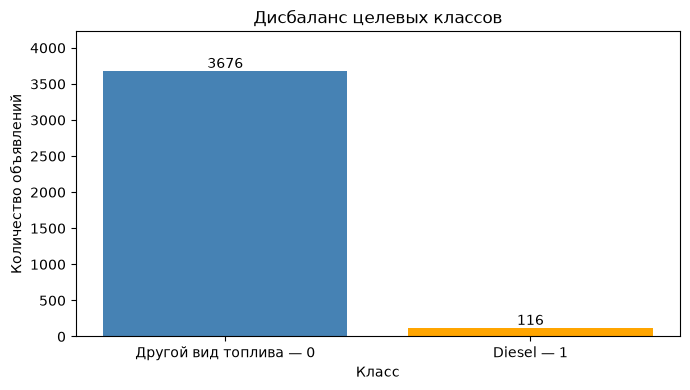

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(
    ["Другой вид топлива — 0", "Diesel — 1"],
    counts.to_numpy(),
    color=["steelblue", "orange"],
)

ax.set_title("Дисбаланс целевых классов")
ax.set_xlabel("Класс")
ax.set_ylabel("Количество объявлений")

for position, value in enumerate(counts.to_numpy()):
    ax.text(position, value, str(value), ha="center", va="bottom")

ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout()
plt.show()

Дизельные автомобили составляют около 3,06% размеченных данных.

Классификатор, который всегда отвечает «не дизель»,
получит accuracy около 96,94%, но не обнаружит ни одного
дизельного автомобиля.

Поэтому одной accuracy недостаточно.
Необходимо анализировать precision, recall и F1 класса Diesel.

In [5]:
data["mileage_numeric"] = pd.to_numeric(
    data["milage"]
    .astype("string")
    .str.replace(r"[^\d.]", "", regex=True),
    errors="coerce",
)

data["model_year"] = pd.to_numeric(
    data["model_year"],
    errors="coerce",
)

numeric_features = [
    "model_year",
    "mileage_numeric",
]

categorical_features = [
    "brand",
    "transmission",
    "accident",
    "clean_title",
]

features = numeric_features + categorical_features

X = data[features].copy()
y = data["is_diesel"].copy()

assert "fuel_type" not in X.columns
assert "is_diesel" not in X.columns

print("Размер X:", X.shape)
print("Пропуски:")
display(X.isna().sum())

display(X.head())

Размер X: (3792, 6)
Пропуски:


model_year           0
mileage_numeric      0
brand                0
transmission         0
accident           108
clean_title        569
dtype: int64

,model_year,mileage_numeric,brand,transmission,accident,clean_title
0,2013,51000.0,Ford,6-Speed A/T,At least 1 accident or damage reported,Yes
1,2021,34742.0,Hyundai,8-Speed Automatic,At least 1 accident or damage reported,Yes
2,2022,22372.0,Lexus,Automatic,None reported,NaN
3,2015,88900.0,INFINITI,7-Speed A/T,None reported,Yes
4,2021,9835.0,Audi,8-Speed Automatic,None reported,NaN


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

print("\nКлассы в train:")
display(y_train.value_counts().sort_index())

print("\nКлассы в test:")
display(y_test.value_counts().sort_index())

Train: (3033, 6)
Test: (759, 6)

Классы в train:


is_diesel
0    2940
1      93
Name: count, dtype: int64


Классы в test:


is_diesel
0    736
1     23
Name: count, dtype: int64

In [7]:
def make_model(class_weight=None):
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    categorical_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Unknown",
            ),
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore"),
        ),
    ])

    preprocessing = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        (
            "categorical",
            categorical_pipeline,
            categorical_features,
        ),
    ])

    return Pipeline([
        ("preprocessing", preprocessing),
        (
            "classifier",
            LogisticRegression(
                class_weight=class_weight,
                solver="lbfgs",
                max_iter=3000,
            ),
        ),
    ])

In [8]:
def random_undersample(X_part, y_part, random_state):
    rng = np.random.default_rng(random_state)

    labels = y_part.to_numpy()

    diesel_positions = np.flatnonzero(labels == 1)
    other_positions = np.flatnonzero(labels == 0)

    if len(diesel_positions) == 0:
        raise ValueError("В обучающей части нет дизельных автомобилей.")

    if len(other_positions) < len(diesel_positions):
        raise ValueError("Ожидалось, что класс 0 является большинством.")

    selected_other = rng.choice(
        other_positions,
        size=len(diesel_positions),
        replace=False,
    )

    selected = np.concatenate([
        diesel_positions,
        selected_other,
    ])

    rng.shuffle(selected)

    return (
        X_part.iloc[selected].copy(),
        y_part.iloc[selected].copy(),
    )

In [9]:
X_demo, y_demo = random_undersample(
    X_train,
    y_train,
    random_state=42,
)

print("До undersampling:", len(y_train))
print("После undersampling:", len(y_demo))
display(y_demo.value_counts().sort_index())

До undersampling: 3033
После undersampling: 186


is_diesel
0    93
1    93
Name: count, dtype: int64

In [10]:
methods = [
    "baseline",
    "class_weight",
    "undersampling",
]


def fit_method(method, X_part, y_part, random_state):
    if method == "baseline":
        model = make_model(class_weight=None)
        model.fit(X_part, y_part)

    elif method == "class_weight":
        model = make_model(class_weight="balanced")
        model.fit(X_part, y_part)

    elif method == "undersampling":
        X_small, y_small = random_undersample(
            X_part,
            y_part,
            random_state=random_state,
        )

        model = make_model(class_weight=None)
        model.fit(X_small, y_small)

    else:
        raise ValueError(f"Неизвестный метод: {method}")

    return model

In [11]:
THRESHOLD = 0.5


def predict_at_threshold(model, X_part):
    probabilities = model.predict_proba(X_part)[:, 1]

    predictions = (
        probabilities >= THRESHOLD
    ).astype(int)

    return predictions


def calculate_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0,
        ),
        "recall": recall_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0,
        ),
        "f1": f1_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0,
        ),
    }

## Порог классификации

Во всех вариантах используется фиксированный порог 0,5.

Точная стоимость FP и FN в постановке не задана.
Цель эксперимента — сравнить методы коррекции дисбаланса
при одинаковом правиле получения классов.

Поэтому порог заранее зафиксирован и не подбирается по test.
Порог 0,5 допустим для этого контролируемого учебного сравнения,
но его оптимальность по практической стоимости ошибок не утверждается.

После применения весов классов или undersampling оценки вероятностей
могут быть некалиброванными относительно исходной доли Diesel.
Поэтому значение 0,5 не интерпретируется как гарантия
реальной вероятности 50%.

In [12]:
cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=42,
)

splits = list(cv.split(X_train, y_train))

rows = []

for split_id, (train_positions, val_positions) in enumerate(splits):
    X_fit = X_train.iloc[train_positions]
    y_fit = y_train.iloc[train_positions]

    X_val = X_train.iloc[val_positions]
    y_val = y_train.iloc[val_positions]

    for method in methods:
        model = fit_method(
            method,
            X_fit,
            y_fit,
            random_state=1000 + split_id,
        )

        predictions = predict_at_threshold(model, X_val)
        metrics = calculate_metrics(y_val, predictions)

        rows.append({
            "split": split_id,
            "method": method,
            **metrics,
        })

    print(f"Завершено разбиение {split_id + 1}/{len(splits)}")

cv_results = pd.DataFrame(rows)

display(cv_results.head())

Завершено разбиение 1/15
Завершено разбиение 2/15
Завершено разбиение 3/15
Завершено разбиение 4/15
Завершено разбиение 5/15
Завершено разбиение 6/15
Завершено разбиение 7/15
Завершено разбиение 8/15
Завершено разбиение 9/15
Завершено разбиение 10/15
Завершено разбиение 11/15
Завершено разбиение 12/15
Завершено разбиение 13/15
Завершено разбиение 14/15
Завершено разбиение 15/15


,split,method,accuracy,precision,recall,f1
0,0,baseline,0.967051,0.000000,0.000000,0.000000
1,0,class_weight,0.764415,0.112500,0.947368,0.201117
2,0,undersampling,0.700165,0.090452,0.947368,0.165138
3,1,baseline,0.968699,0.000000,0.000000,0.000000
4,1,class_weight,0.779242,0.108844,0.842105,0.192771


In [13]:
metric_columns = [
    "accuracy",
    "precision",
    "recall",
    "f1",
]

cv_summary = (
    cv_results
    .groupby("method")[metric_columns]
    .agg(["mean", "std"])
    .reindex(methods)
)

display(cv_summary.round(4))

accuracy         precision          recall              f1  \
                  mean     std      mean     std    mean     std    mean   
method                                                                     
baseline        0.9698  0.0020    0.3000  0.4551  0.0288  0.0500  0.0517   
class_weight    0.7800  0.0144    0.1014  0.0111  0.7844  0.0940  0.1794   
undersampling   0.7493  0.0310    0.0857  0.0134  0.7339  0.1038  0.1532   

                       
                  std  
method                 
baseline       0.0877  
class_weight   0.0195  
undersampling  0.0226

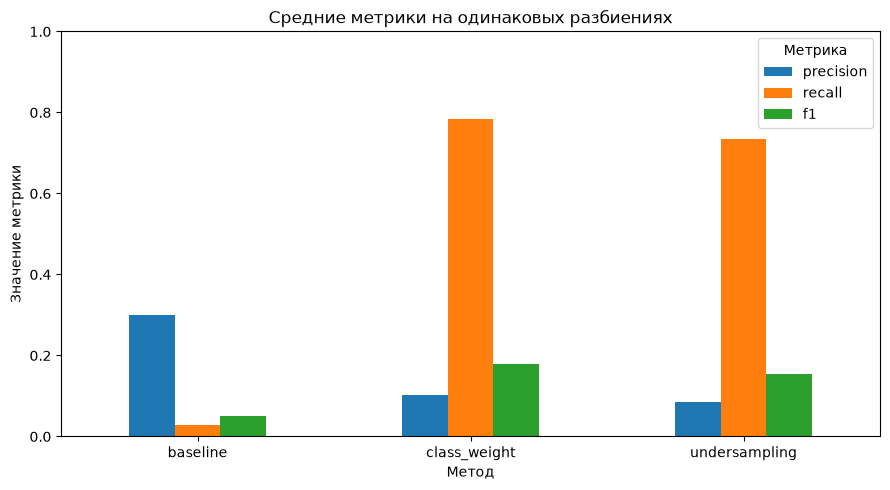

In [14]:
means = (
    cv_results
    .groupby("method")[["precision", "recall", "f1"]]
    .mean()
    .reindex(methods)
)

ax = means.plot.bar(
    figsize=(9, 5),
    rot=0,
)

ax.set_title("Средние метрики на одинаковых разбиениях")
ax.set_xlabel("Метод")
ax.set_ylabel("Значение метрики")
ax.set_ylim(0, 1)
ax.legend(title="Метрика")

plt.tight_layout()
plt.show()

In [15]:
paired_rows = []

for metric in ["precision", "recall", "f1"]:
    wide = cv_results.pivot(
        index="split",
        columns="method",
        values=metric,
    )

    for method in ["class_weight", "undersampling"]:
        differences = wide[method] - wide["baseline"]

        paired_rows.append({
            "method": method,
            "metric": metric,
            "mean_difference": differences.mean(),
            "std_difference": differences.std(),
            "better_splits": int((differences > 0).sum()),
            "equal_splits": int(
                np.isclose(differences, 0).sum()
            ),
            "total_splits": len(differences),
        })

paired_summary = pd.DataFrame(paired_rows)

display(paired_summary.round(4))

,method,metric,mean_difference,std_difference,better_splits,equal_splits,total_splits
0,class_weight,precision,-0.1986,0.4511,10,0,15
1,undersampling,precision,-0.2143,0.4537,10,0,15
2,class_weight,recall,0.7556,0.0971,15,0,15
3,undersampling,recall,0.7051,0.1088,15,0,15
4,class_weight,f1,0.1277,0.0835,14,0,15
5,undersampling,f1,0.1015,0.0907,13,0,15


In [16]:
mean_f1 = (
    cv_results
    .groupby("method")["f1"]
    .mean()
    .reindex(methods)
)

selected_method = mean_f1.idxmax()

print("Средний F1:")
display(mean_f1.round(4))

print("Выбранный метод:", selected_method)

Средний F1:


method
baseline         0.0517
class_weight     0.1794
undersampling    0.1532
Name: f1, dtype: float64

Выбранный метод: class_weight


In [17]:
final_models = {}
test_predictions = {}
test_rows = []

for method in methods:
    model = fit_method(
        method,
        X_train,
        y_train,
        random_state=42,
    )

    predictions = predict_at_threshold(model, X_test)

    final_models[method] = model
    test_predictions[method] = predictions

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1],
    ).ravel()

    test_rows.append({
        "method": method,
        **calculate_metrics(y_test, predictions),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
    })

test_results = (
    pd.DataFrame(test_rows)
    .set_index("method")
    .reindex(methods)
)

display(test_results.round(4))

print("Метод, заранее выбранный по CV:", selected_method)

,accuracy,precision,recall,f1,TN,FP,FN,TP
method,,,,,,,,
baseline,0.9697,0.0000,0.0000,0.0000,736,0,23,0
class_weight,0.7655,0.0942,0.7826,0.1682,563,173,5,18
undersampling,0.7615,0.1010,0.8696,0.1810,558,178,3,20


Метод, заранее выбранный по CV: class_weight


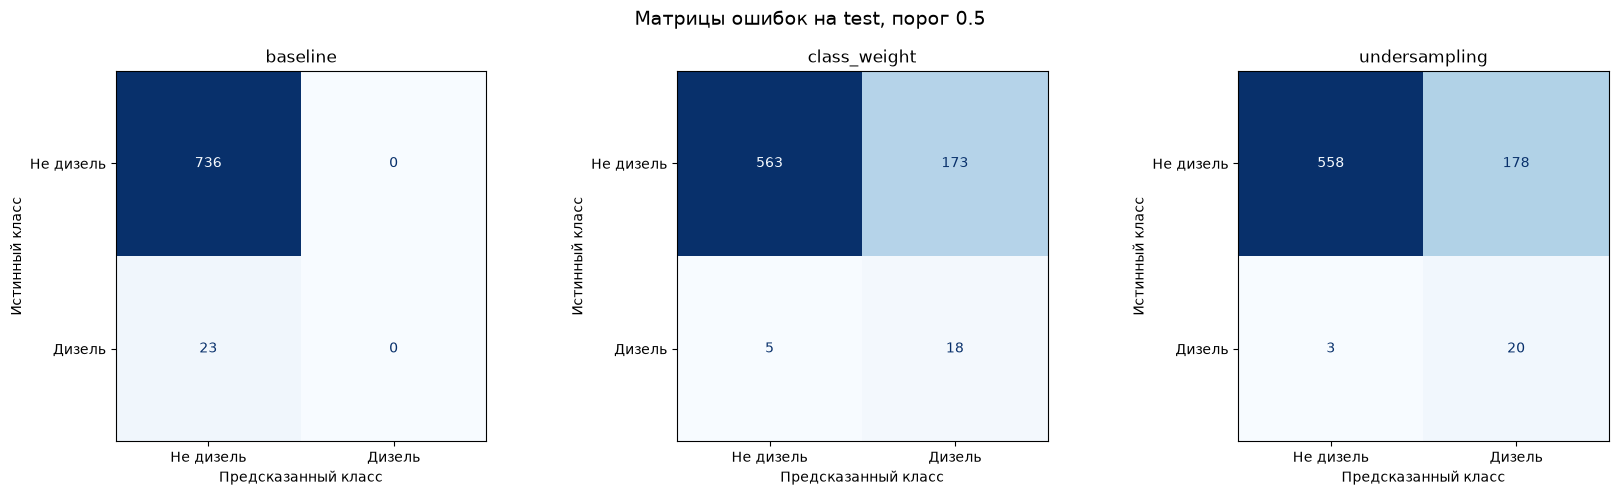

In [18]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 5),
)

for ax, method in zip(axes, methods):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        test_predictions[method],
        labels=[0, 1],
        display_labels=["Не дизель", "Дизель"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )

    ax.set_title(method)
    ax.set_xlabel("Предсказанный класс")
    ax.set_ylabel("Истинный класс")

fig.suptitle(
    f"Матрицы ошибок на test, порог {THRESHOLD}",
    fontsize=14,
)

plt.tight_layout()
plt.show()

## Интерпретация матрицы ошибок

TN — автомобиль с другим известным топливом правильно
определён как недизельный.

FP — автомобиль с другим известным топливом ошибочно
определён как дизельный.

FN — дизельный автомобиль ошибочно определён как недизельный.

TP — дизельный автомобиль правильно определён как дизельный.

## Матрица ошибок выбранной модели

По результатам кросс-валидации выбрана логистическая регрессия
с class_weight="balanced".

На тестовой выборке при пороге 0,5 получены:

- TN = 563: недизельные автомобили правильно определены как недизельные.
- FP = 173: недизельные автомобили ошибочно названы дизельными.
- FN = 5: дизельные автомобили ошибочно названы недизельными.
- TP = 18: дизельные автомобили правильно определены как дизельные.

Модель обнаружила 18 из 23 дизельных автомобилей,
но ошибочно включила в дизельный класс ещё 173 автомобиля.

Precision = 0,0942: среди 191 автомобиля, названного дизельным,
только 18 действительно дизельные — около 9,42%.

Recall = 0,7826: модель обнаружила около 78,26% настоящих
дизельных автомобилей.

F1 = 0,1682: несмотря на достаточно высокий recall,
итоговая оценка остаётся низкой из-за большого количества FP.

Accuracy = 0,7655: правильно классифицированы 581 из 759 автомобилей,
то есть около 76,55%.

Для сравнения, базовая модель получила accuracy = 0,9697,
но не обнаружила ни одного дизельного автомобиля.
Она отнесла все тестовые объявления к классу «не дизель».

Следовательно, высокая accuracy базовой модели объясняется
преобладанием недизельных автомобилей и не означает,
что модель успешно распознаёт редкий класс.

## Итоговое сравнение

### Базовая модель

Средние метрики на кросс-валидации:

- accuracy = 0,9698;
- precision = 0,3000;
- recall = 0,0288;
- F1 = 0,0517.

Базовая модель без коррекции дисбаланса практически не обнаруживает
дизельные автомобили: средний recall составляет только 2,88%.

Высокая accuracy около 96,98% связана с преобладанием класса
«не дизель».

Средняя precision = 0,3000 не означает, что модель хорошо решает задачу.
Она обнаруживает очень мало положительных объектов, а precision
сильно меняется между разбиениями: стандартное отклонение равно 0,4551.
Основная проблема модели — пропуск почти всех дизельных автомобилей.

На test модель не обнаружила ни одного из 23 дизельных автомобилей:
precision, recall и F1 равны нулю.

### Class weight

Средние метрики на кросс-валидации:

- precision = 0,1014;
- recall = 0,7844;
- F1 = 0,1794.

По сравнению с baseline:

- precision снизилась в среднем на 0,1986;
- recall увеличился в среднем на 0,7556;
- F1 увеличилась в среднем на 0,1277.

Механизм метода: редкий класс получает больший вес в функции потерь.
Ошибки на дизельных автомобилях сильнее влияют на обучение,
при этом сохраняются все обучающие наблюдения.

В эксперименте модель стала значительно чаще обнаруживать
дизельные автомобили: средний recall вырос с 2,88% до 78,44%.
Однако вместе с этим увеличилось количество ложноположительных
ответов, поэтому precision осталась низкой — около 10,14%.

Таким образом, метод улучшил обнаружение редкого класса,
но не обеспечил высокую точность списка найденных дизельных автомобилей.

### Undersampling

Средние метрики на кросс-валидации:

- precision = 0,0857;
- recall = 0,7339;
- F1 = 0,1532.

По сравнению с baseline:

- precision снизилась в среднем на 0,2143;
- recall увеличился в среднем на 0,7051;
- F1 увеличилась в среднем на 0,1015.

Механизм метода: случайно сокращается количество объектов большинства,
и соотношение классов в обучающей части становится 1:1.
Проверочные данные сохраняют исходный дисбаланс.

В эксперименте undersampling улучшил обнаружение дизельных автомобилей
по сравнению с baseline, но средние precision, recall и F1
оказались ниже, чем у class_weight.

Недостаток метода — потеря части обучающих данных.
При финальном обучении вместо 3033 объявлений использовались только 186:
93 дизельных и 93 недизельных.

Сокращение данных является возможным объяснением уступающего результата.
Однако отдельно влияние объёма данных в этом эксперименте не проверялось.

### Устойчивость результата

Все методы проверялись на одинаковых 15 разбиениях:
5 частей и 3 повторения стратифицированной кросс-валидации.

Заполнение пропусков, масштабирование и кодирование категорий
обучались заново внутри каждой обучающей части.
Undersampling применялся только к обучающей части.

Для class_weight средняя разница F1 относительно baseline
составила +0,1277.
Улучшение F1 наблюдалось на 14 из 15 разбиений.

Для undersampling средняя разница F1 относительно baseline
составила +0,1015.
Улучшение F1 наблюдалось на 13 из 15 разбиений.

Оба метода повысили recall относительно baseline
на всех 15 разбиениях.

Стандартное отклонение F1 составило:

- baseline — 0,0877;
- class_weight — 0,0195;
- undersampling — 0,0226.

Следовательно, улучшение обнаружения редкого класса наблюдается
на разных разбиениях и не ограничивается одним удачным разделением данных.

Результаты согласуются с механизмами коррекции дисбаланса:
повышением веса редкого класса и сокращением большинства.
Остальные настройки классификатора и схема проверки были одинаковыми.

Однако повторные разбиения используют пересекающиеся данные.
Это не является формальным доказательством статистической значимости
или гарантией такого же качества на новых данных.

### Предпочтительный вариант

По заранее выбранной основной метрике F1 на кросс-валидации
предпочтительным вариантом является class_weight="balanced".

Средний F1 этого метода равен 0,1794:
выше, чем у undersampling — 0,1532,
и baseline — 0,0517.

У class_weight также выше средние precision и recall,
чем у undersampling, и немного меньше разброс F1.
Кроме того, метод сохраняет все обучающие наблюдения.

На финальном test для class_weight получены:

- precision = 0,0942;
- recall = 0,7826;
- F1 = 0,1682.

При этом undersampling на данном test показал более высокий F1 = 0,1810
и recall = 0,8696.

Это расхождение необходимо учитывать:
преимущество class_weight по средней валидации
не гарантирует победу на каждом отдельном разбиении.

Выбор метода сохраняется за class_weight,
поскольку он был сделан по кросс-валидации до оценки на test.
Использовать test для повторного выбора метода было бы некорректно.

### Ограничения и практическая применимость

В test только 23 дизельных автомобиля.
Одна дополнительная ошибка изменяет recall примерно
на 4,35 процентного пункта.

Precision выбранной модели составляет только 9,42%.
Большинство автомобилей, названных дизельными, на самом деле недизельные.
Поэтому модель пока не подходит для автоматического заполнения
типа топлива без дополнительной проверки.

Результаты относятся к объявлениям с известной меткой топлива.
Качество на объявлениях с неизвестным топливом отдельно не проверено.

Во всех вариантах использован фиксированный порог 0,5.
Он позволяет сравнить методы при одинаковом правиле получения классов.
Точная стоимость FP и FN не задана,
поэтому оптимальность этого порога по практической цене ошибок
не утверждается.